## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

In [117]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [118]:
# Set the path to your dataset in Google Drive (edit the folder name below)
DATA_PATH = "/content/drive/MyDrive/ANN-LAB04/ANN-dataset-LAB04/processed.cleveland.data"


## Cell 2 — Import Libraries

In [119]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)


## Cell 3 — Load Dataset

In [120]:
# TODO: Load the UCI Heart Disease dataset from DATA_PATH
# The raw UCI file has no header row and uses '?' for missing values -- handle both.
df = pd.read_csv(DATA_PATH, header=None, na_values='?')

df = df.dropna()

# Convert target to binary
df[13] = (df[13] > 0).astype(int)




## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there?
- What are the column names and data types?
- What do the first 5 rows look like?
- What are the descriptive statistics (`describe()`)?
- What is the target variable and what values does it take?



In [121]:
# TODO: Inspect shape, columns, dtypes, head(), and describe()

print(df.shape)

print(df.columns)

print(df.dtypes)

print(df.head())

print(df.describe())

#**Target variable: The target variable is the last column (column 13), which represents the presence or absence of heart disease**

(297, 14)
Index([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13], dtype='int64')
0     float64
1     float64
2     float64
3     float64
4     float64
5     float64
6     float64
7     float64
8     float64
9     float64
10    float64
11    float64
12    float64
13      int64
dtype: object
     0    1    2      3      4    5    6      7    8    9    10   11   12  13
0  63.0  1.0  1.0  145.0  233.0  1.0  2.0  150.0  0.0  2.3  3.0  0.0  6.0   0
1  67.0  1.0  4.0  160.0  286.0  0.0  2.0  108.0  1.0  1.5  2.0  3.0  3.0   1
2  67.0  1.0  4.0  120.0  229.0  0.0  2.0  129.0  1.0  2.6  2.0  2.0  7.0   1
3  37.0  1.0  3.0  130.0  250.0  0.0  0.0  187.0  0.0  3.5  3.0  0.0  3.0   0
4  41.0  0.0  2.0  130.0  204.0  0.0  2.0  172.0  0.0  1.4  1.0  0.0  3.0   0
               0           1           2           3           4           5   \
count  297.000000  297.000000  297.000000  297.000000  297.000000  297.000000   
mean    54.542088    0.676768    3.158249  131.693603  247.350168    0.144781   


## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

13
0    160
1    137
Name: count, dtype: int64
13
0    53.872054
1    46.127946
Name: proportion, dtype: float64
13
0    160
1    137
Name: count, dtype: int64
13
0    53.872054
1    46.127946
Name: proportion, dtype: float64


<Axes: xlabel='13', ylabel='count'>

<Axes: xlabel='13', ylabel='count'>

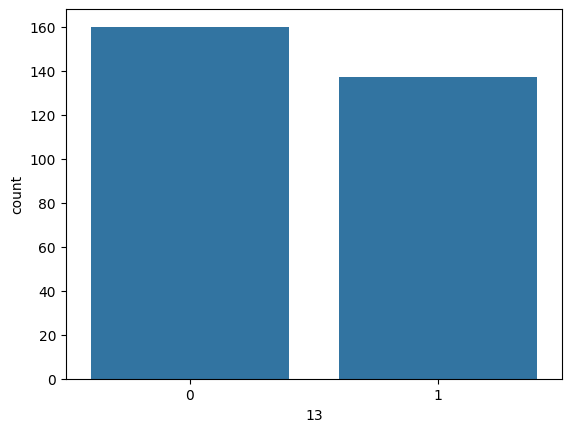

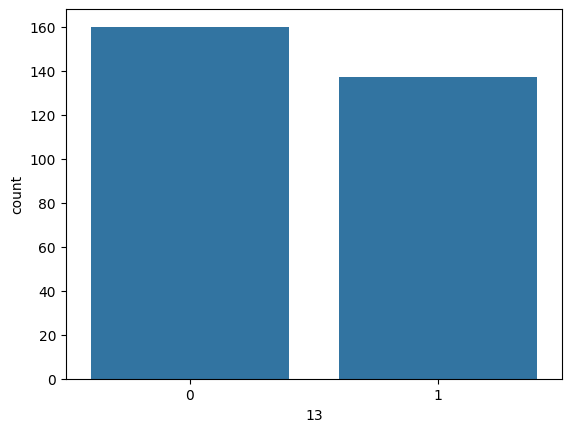

In [122]:
print(df[13].value_counts())
print(df[13].value_counts(normalize=True) * 100)
sns.countplot(x=df[13])



#the dataset is imbalanced.
#the 0 class holds the majority of the data (about 54%).





## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).

In [123]:
# TODO: Check for missing values, duplicates, dtypes, and unique values per column

print(df.isnull().sum())

print("#########################################")
print(df.duplicated().sum())

print("#########################################")
print(df.dtypes)

print("#########################################")
print(df.nunique())





0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
dtype: int64
#########################################
0
#########################################
0     float64
1     float64
2     float64
3     float64
4     float64
5     float64
6     float64
7     float64
8     float64
9     float64
10    float64
11    float64
12    float64
13      int64
dtype: object
#########################################
0      41
1       2
2       4
3      50
4     152
5       2
6       3
7      91
8       2
9      40
10      3
11      4
12      3
13      2
dtype: int64


## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

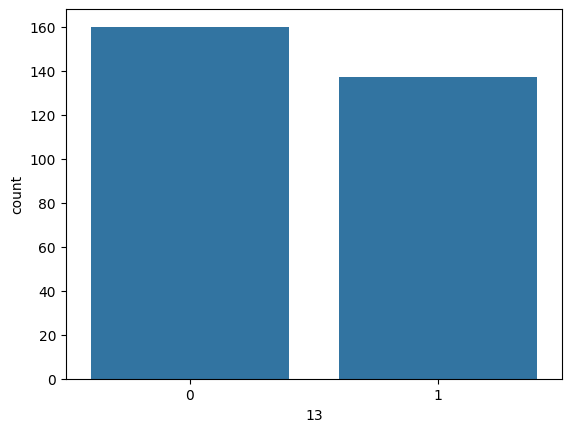

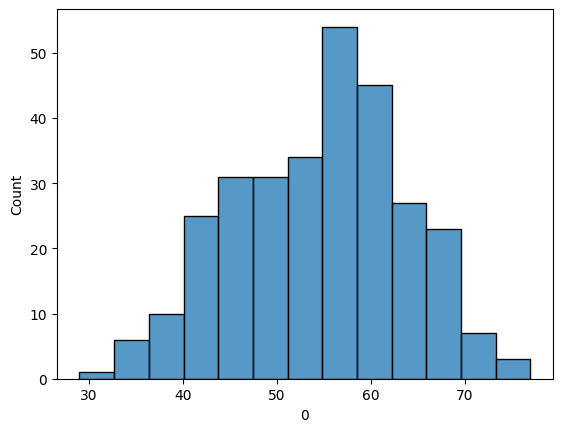

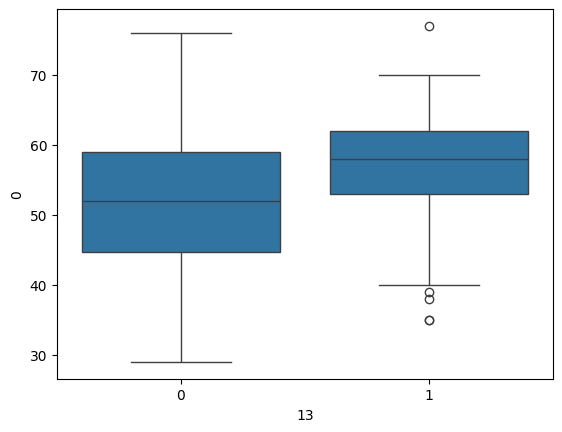

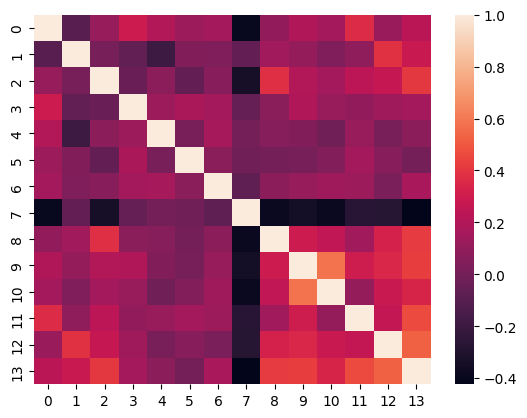

In [124]:
# TODO: Create the required visualizations


# 1. Target distribution plot
sns.countplot(x=df[13])
plt.show()

# 2. Age distribution (Column 0 is Age)
sns.histplot(x=df[0])
plt.show()

# 3. Age vs Target (Column 0 vs Column 13)
sns.boxplot(x=df[13], y=df[0])
plt.show()

# 4. Correlation heatmap
sns.heatmap(df.corr())
plt.show()



## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [125]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

# Define X and y
X = df.drop(columns=[13])
y = df[13]



# Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert to PyTorch tensors
X_train = torch.tensor(X_train.values, dtype=torch.float32)
X_test = torch.tensor(X_test.values, dtype=torch.float32)

y_train = torch.tensor(y_train.values, dtype=torch.float32)
y_test = torch.tensor(y_test.values, dtype=torch.float32)




In [126]:
# Create TensorDatasets
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)


## Cell 9 — Design Your Own Neural Network

Design a neural network with **4-5 layers total** (input + hidden layers + output). Decide the number of neurons, hidden layers, and activation functions.

Fill in the table with your design:

| Layer    | Neurons | Activation |
|----------|--------:|------------|
| Input    |  13      |  none          |
| Hidden 1 |  16      |  ReLU          |
| Hidden 2 |  8       |  ReLU          |
| Output   |  1       |  Sigmoid       |

*(Delete rows you don't use if your design has fewer than 4 hidden layers.)*

## Cell 10 — Manually Calculate Parameters

For **each layer** in your design above, manually calculate the number of trainable parameters using:

`Parameters = (Input units × Output units) + Output units`

Complete the table:

| Layer    | Input Units | Output Units | Calculation | Parameters |
|----------|------------:|-------------:|-------------|-----------:|
| Hidden 1 | 13   | 16 |    13*16+16  | 224           |
| Hidden 2 | 16   | 8 |     16*8+8 |    136        |
| Output   | 8    |1  |     8*1+1  |    9        |
| **Total**|             |               |   |       369      |

Later, compare this total to what `model.summary()` reports in Cell 11.

## Cell 11 — Implement Neural Network in PyTorch


In [127]:
class MyModel(nn.Module):
    def __init__(self, input_dim, hidden_dim1, hidden_dim2, output_dim):
        super().__init__()
        self.model = nn.Sequential(
            # Input → Hidden 1
            nn.Linear(input_dim, hidden_dim1),
            nn.ReLU(),
            # Hidden 1-Hidden 2
            nn.Linear(hidden_dim1, hidden_dim2),
            nn.ReLU(),
            # Hidden 2-Output
            nn.Linear(hidden_dim2, output_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

# Create model
model = MyModel(input_dim=13, hidden_dim1=16, hidden_dim2=8, output_dim=1)

print(model)


MyModel(
  (model): Sequential(
    (0): Linear(in_features=13, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.


BCE LOSS
This is a binary classification task (disease or no disease), so we need a loss function designed for binary outputs. Since our model already has a Sigmoid activation at the output layer (which converts the output to a probability between 0 and 1), BCELoss is the perfect match as it measures the difference between that predicted probability and the true label (0 or 1).



In [128]:
# TODO: Choose an appropriate loss function
loss_function = nn.BCELoss()



## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.


Adam (Adaptive Moment Estimation)

Justification: Adam is chosen because it automatically adjusts the learning rate for each parameter during training, making it faster and more efficient than basic optimizers like SGD. It works well on small datasets like this one and requires very little tuning. I used a learning rate of 0.001 which is the standard default and works well in most cases.

In [129]:
# TODO: Choose an optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)



## Cell 14 — Compile the Model

In [130]:
num_epochs = 100
train_losses = []
val_losses = []

for epoch in range(num_epochs):

    model.train()

    for X, y in train_loader:
        optimizer.zero_grad()
        outputs = model(X).squeeze()
        loss = loss_function(outputs, y)
        loss.backward()
        optimizer.step()

    train_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        for X_val, y_val in test_loader:
            val_loss = loss_function(model(X_val).squeeze(), y_val)
    val_losses.append(val_loss.item())

print("Done!")


Done!


## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

**No signs of overfitting. Both training and validation loss decrease together over 100 epochs. The training loss appears spiky because it is recorded per batch, but overall both losses trend downward, meaning the model is learning well.**

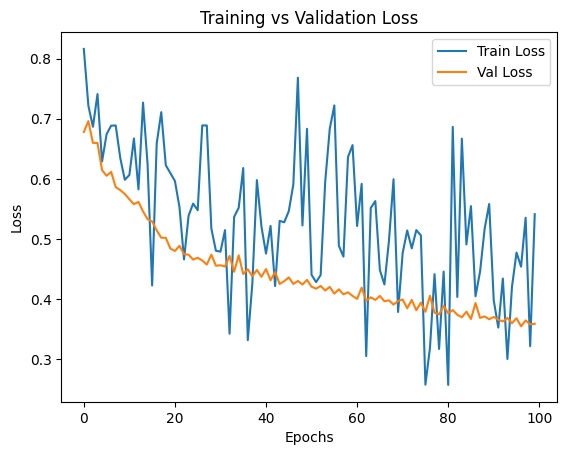

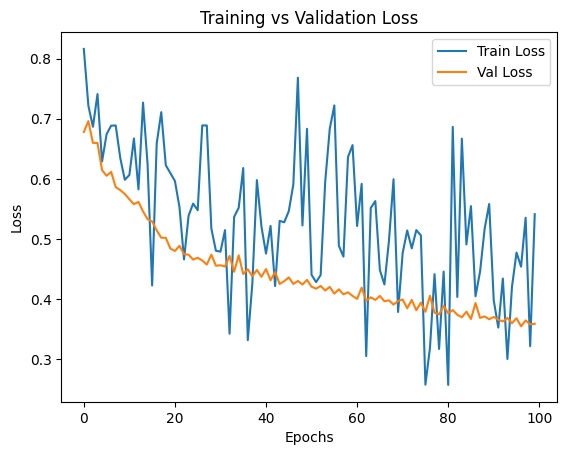

In [131]:
# TODO: Plot training and validation loss from `history`


plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()



## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.

In [137]:
#Removed the torch.sigmoid() line and the probabilities variable since our model already has Sigmoid built in at the end.



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import torch

# Put model in evaluation mode
model.eval()

y_true = []
y_prob = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        # Model predictions (already has Sigmoid inside, so no need to apply again)
        outputs = model(X_batch).squeeze()

        y_prob.extend(outputs.cpu().numpy())
        y_true.extend(y_batch.cpu().numpy())

# Convert probabilities to binary predictions
threshold = 0.5
y_pred_nn = [1 if p >= threshold else 0 for p in y_prob]

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred_nn)
precision = precision_score(y_true, y_pred_nn, zero_division=0)
recall = recall_score(y_true, y_pred_nn, zero_division=0)
f1 = f1_score(y_true, y_pred_nn, zero_division=0)

# Display results
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")


Accuracy : 0.9000
Precision: 0.9231
Recall   : 0.8571
F1-score : 0.8889


## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [139]:
# Create and train AdaBoost model
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)
ada_model.fit(X_train.numpy(), y_train.numpy())

# Predict on test data
y_pred_ada = ada_model.predict(X_test.numpy())

# Calculate and display metrics
print(f"Accuracy : {accuracy_score(y_test.numpy(), y_pred_ada):.4f}")
print(f"Precision: {precision_score(y_test.numpy(), y_pred_ada, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test.numpy(), y_pred_ada, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test.numpy(), y_pred_ada, zero_division=0):.4f}")


Accuracy : 0.8500
Precision: 0.8519
Recall   : 0.8214
F1-score : 0.8364


## Cell 19 — Compare Both Models

Fill in your results:

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network |      0.90 |0.92 | 0.85       |   0.89       |
| AdaBoost       |       0.85   | 0.85  |  0.82      | 0.83         |

Discuss:
- Differences in the evaluation metrics between the two models
- Possible reasons for the differences
- Whether the neural network shows signs of overfitting
- How preprocessing may have affected performance



**Differences in evaluation metrics: The Neural Network performed better than AdaBoost across all metrics (90% vs 85% accuracy).**

Possible reasons for the differences: The Neural Network has multiple layers that learn complex patterns, while AdaBoost is a simpler model built from weak trees.
**bold text**
**Signs of overfitting: No, both train and validation loss went down together, so the model generalized well.**

**How preprocessing affected performance: Scaling the data helped the Neural Network learn faster. AdaBoost does not need scaling so preprocessing had little effect on it. **

In [134]:
# TODO: Optionally build a small DataFrame to display the comparison table


## Cell 20 — Final Interpretation

In a few sentences each, discuss:
1. Whether the dataset is balanced or imbalanced
2. The important preprocessing steps you applied
3. Your neural network architecture and design choices
4. Neural network evaluation results
5. AdaBoost evaluation results
6. Comparison between the two models
7. Possible improvements for future work

**1. Dataset balance:**
The dataset is slightly imbalanced. After converting to binary, class 0 has around 54% and class 1 has around 46%, which is close enough that I did not need any special handling.

**2. Preprocessing steps:**
I dropped rows with missing values, scaled the numerical features, and made sure to split the data before any preprocessing so no test data leaked into training.

**3. Neural network architecture:**
I built a simple 3 layer network with 13 inputs, two hidden layers (16 and 8 neurons with ReLU), and 1 output with Sigmoid. I kept it small on purpose since the dataset is small and I did not want it to overfit.

**4. Neural network results:**
The model did very well with 90% accuracy, 92% precision, 85% recall, and 88% F1-score.

**5. AdaBoost results:**
AdaBoost got 85% accuracy, 85% precision, 82% recall, and 83% F1-score. Not bad but a bit lower than the neural network.

**6. Comparison:**
The Neural Network beat AdaBoost across all 4 metrics. I think this is because the neural network could pick up on more complex patterns in the data.

**7. Possible improvements:**
In the future I could try adding Dropout layers, training for more epochs, or experimenting with a deeper network to see if the results improve further.